Script to convert Qiskit weights from pt to npz format

In [ ]:
import torch, numpy as np
obj = torch.load("/content/hybrid_QML_3class_4qubit_8depth_basic_entangler_qiskit.pt", map_location="cpu", weights_only=False)
sd = obj["state_dict"] if isinstance(obj, dict) and "state_dict" in obj else obj
np.savez("hybrid_QML_3class_4qubit_8depth_basic_entangler.npz", **{k: v.numpy() for k, v in sd.items()})
print(list(sd.keys()))

['fc1.weight', 'fc1.bias', 'bn1.weight', 'bn1.bias', 'bn1.running_mean', 'bn1.running_var', 'bn1.num_batches_tracked', 'fc2.weight', 'fc2.bias', 'bn2.weight', 'bn2.bias', 'bn2.running_mean', 'bn2.running_var', 'bn2.num_batches_tracked', 'fc3.weight', 'fc3.bias', 'bn3.weight', 'bn3.bias', 'bn3.running_mean', 'bn3.running_var', 'bn3.num_batches_tracked', 'pre_net.weight', 'pre_net.bias', 'qlayer._weights', 'post_net.weight', 'post_net.bias']


Pennylane to qiskit

In [6]:
import torch
FILENAME = "hybrid_QML_3class_8qubit_4depth_basic_entangler"
SRC = f"/content/{FILENAME}.pt"          # PennyLane-format weights
DST = f"{FILENAME}_qiskit.pt"   # Qiskit-format output
N_QUBITS, N_REPS = 8, 4

def pennylane_to_qiskit(sd):
    out = {}
    for k, v in sd.items():
        if k == "qlayer.weights":
            assert tuple(v.shape) == (N_REPS, N_QUBITS), f"unexpected shape {tuple(v.shape)}"
            out["qlayer._weights"] = v.detach().cpu().reshape(-1).clone().float()   # row-major: rep*N_QUBITS + qubit
        else:
            out[k] = v.detach().cpu().clone()
    return out

def qiskit_to_pennylane(sd):                       # reverse direction, if you ever need it
    out = {}
    for k, v in sd.items():
        if k == "qlayer._weights":
            out["qlayer.weights"] = v.detach().cpu().reshape(N_REPS, N_QUBITS).clone().float()
        else:
            out[k] = v.detach().cpu().clone()
    return out

obj = torch.load(SRC, map_location="cpu", weights_only=False)
has_ckpt = isinstance(obj, dict) and "state_dict" in obj          # full checkpoint or bare state_dict
pl_sd = obj["state_dict"] if has_ckpt else obj
print("PennyLane quantum keys:", {k: tuple(v.shape) for k, v in pl_sd.items() if k.startswith("qlayer")})

qk_sd = pennylane_to_qiskit(pl_sd)
print("Qiskit quantum keys:   ", {k: tuple(v.shape) for k, v in qk_sd.items() if k.startswith("qlayer")})

meta = {k: v for k, v in obj.items() if k != "state_dict"} if has_ckpt else {}
if "kept_cols" in meta:
    meta["kept_cols"] = [str(c) for c in meta["kept_cols"]]       # plain str, safe for torch's weights_only mode
torch.save({"state_dict": qk_sd, "format": "qiskit", **meta}, DST)
print("Saved:", DST)


#Script to convert Qiskit weights from pt to npz format
import torch, numpy as np
obj = torch.load(f"/content/{FILENAME}_qiskit.pt", map_location="cpu", weights_only=False)
sd = obj["state_dict"] if isinstance(obj, dict) and "state_dict" in obj else obj
np.savez(f"{FILENAME}.npz", **{k: v.numpy() for k, v in sd.items()})
print(list(sd.keys()))


PennyLane quantum keys: {'qlayer.weights': (4, 8)}
Qiskit quantum keys:    {'qlayer._weights': (32,)}
Saved: hybrid_QML_3class_8qubit_4depth_basic_entangler_qiskit.pt
['fc1.weight', 'fc1.bias', 'bn1.weight', 'bn1.bias', 'bn1.running_mean', 'bn1.running_var', 'bn1.num_batches_tracked', 'fc2.weight', 'fc2.bias', 'bn2.weight', 'bn2.bias', 'bn2.running_mean', 'bn2.running_var', 'bn2.num_batches_tracked', 'fc3.weight', 'fc3.bias', 'bn3.weight', 'bn3.bias', 'bn3.running_mean', 'bn3.running_var', 'bn3.num_batches_tracked', 'pre_net.weight', 'pre_net.bias', 'qlayer._weights', 'post_net.weight', 'post_net.bias']


In [7]:
import glob
import zipfile
from google.colab import files

# Find all npz files in the content directory
npz_files = glob.glob("/content/*.npz")

if not npz_files:
    print("No .npz files found to download.")
else:
    zip_filename = "qml_weights_npz.zip"
    with zipfile.ZipFile(zip_filename, "w") as zipf:
        for file in npz_files:
            zipf.write(file, arcname=file.split("/")[-1])
            print(f"Added {file} to archive")

    print(f"Downloading {zip_filename}...")
    files.download(zip_filename)

Added /content/hybrid_QML_3class_8qubit_4depth_basic_entangler.npz to archive
Added /content/hybrid_QML_3class_4qubit_4depth_basic_entangler.npz to archive
Added /content/hybrid_QML_3class_8qubit_2depth_basic_entangler.npz to archive
Added /content/hybrid_QML_3class_8qubit_1depth_basic_entangler.npz to archive
Added /content/hybrid_QML_3class_16qubit_1depth_basic_entangler.npz to archive


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

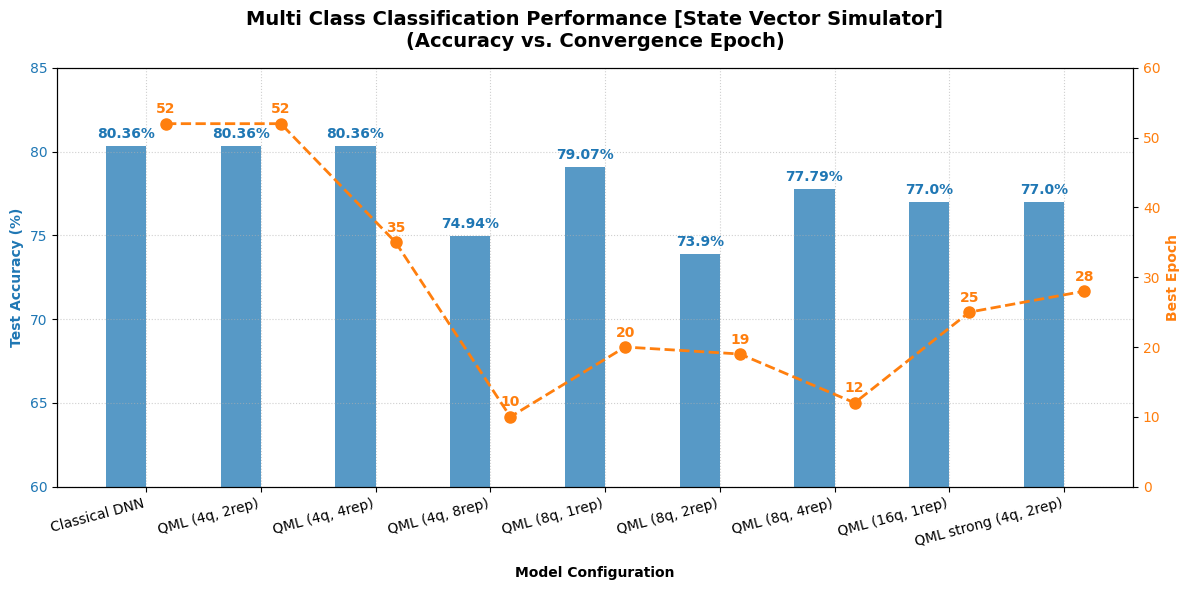

In [14]:
import matplotlib.pyplot as plt
import numpy as np

# Data from the user
models = [
    "Classical DNN",
    "QML (4q, 2rep)",
    "QML (4q, 4rep)",
    "QML (4q, 8rep)",
    "QML (8q, 1rep)",
    "QML (8q, 2rep)",
    "QML (8q, 4rep)",
    "QML (16q, 1rep)",
    "QML strong (4q, 2rep)"
]
accuracies = [80.36, 80.36, 80.36, 74.94, 79.07, 73.90, 77.79, 77.00, 77.00]
epochs = [52, 52, 35, 10, 20, 19, 12, 25, 28]

x = np.arange(len(models))
width = 0.35

fig, ax1 = plt.subplots(figsize=(12, 6))

# Plot Test Accuracy (Primary Y-axis)
color = 'tab:blue'
ax1.set_xlabel('Model Configuration', fontweight='bold', labelpad=12)
ax1.set_ylabel('Test Accuracy (%)', color=color, fontweight='bold')
bars = ax1.bar(x - width/2, accuracies, width, label='Test Accuracy (%)', color=color, alpha=0.75)
ax1.tick_params(axis='y', labelcolor=color)
ax1.set_ylim(60, 85)

# Add values on top of the bars
for bar in bars:
    yval = bar.get_height()
    ax1.text(bar.get_x() + bar.get_width()/2.0, yval + 0.3, f"{yval}%", ha='center', va='bottom', color=color, fontweight='bold')

# Plot Best Epoch (Secondary Y-axis)
ax2 = ax1.twinx()
color = 'tab:orange'
ax2.set_ylabel('Best Epoch', color=color, fontweight='bold')
line = ax2.plot(x + width/2, epochs, marker='o', ls='--', lw=2, color=color, markersize=8, label='Best Epoch')
ax2.tick_params(axis='y', labelcolor=color)
ax2.set_ylim(0, 60)

# Add values above the line markers
for i, txt in enumerate(epochs):
    ax2.annotate(txt, (i + width/2, epochs[i] + 1.5), color=color, fontweight='bold', ha='center')

plt.title('Multi Class Classification Performance [State Vector Simulator]\n(Accuracy vs. Convergence Epoch)', fontsize=14, fontweight='bold', pad=15)
ax1.set_xticks(x)
ax1.set_xticklabels(models, rotation=15, ha='right')
ax1.grid(True, linestyle=':', alpha=0.6)

fig.tight_layout()
plt.show()

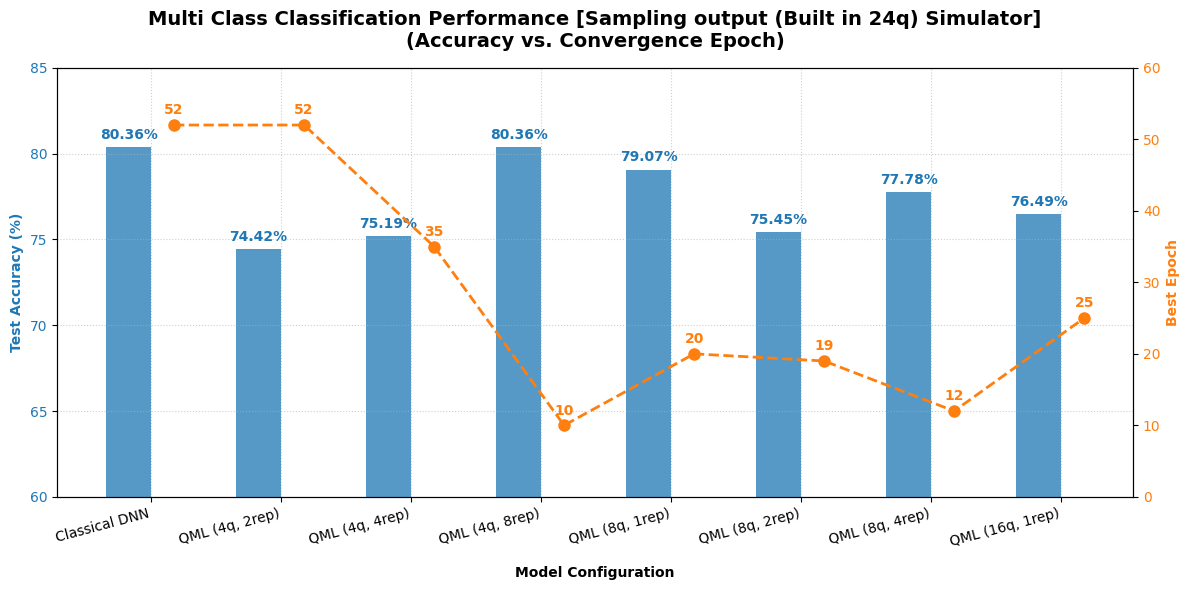

In [12]:
import matplotlib.pyplot as plt
import numpy as np

# Data from the user and evaluation summary
models = [
    "Classical DNN",
    "QML (4q, 2rep)",
    "QML (4q, 4rep)",
    "QML (4q, 8rep)",
    "QML (8q, 1rep)",
    "QML (8q, 2rep)",
    "QML (8q, 4rep)",
    "QML (16q, 1rep)"
]

# Updated accuracies based on the exact evaluation summary:
# 4q 2rep: 74.42%
# 4q 4rep: 75.19%
# 4q 8rep: 80.36%
# 8q 1rep: 79.07%
# 8q 2rep: 75.45%
# 8q 4rep: 77.78%
# 16q 1rep: 76.49%
accuracies = [80.36, 74.42, 75.19, 80.36, 79.07, 75.45, 77.78, 76.49]
epochs = [52, 52, 35, 10, 20, 19, 12, 25]

x = np.arange(len(models))
width = 0.35

fig, ax1 = plt.subplots(figsize=(12, 6))

# Plot Test Accuracy (Primary Y-axis)
color = 'tab:blue'
ax1.set_xlabel('Model Configuration', fontweight='bold', labelpad=12)
ax1.set_ylabel('Test Accuracy (%)', color=color, fontweight='bold')
bars = ax1.bar(x - width/2, accuracies, width, label='Test Accuracy (%)', color=color, alpha=0.75)
ax1.tick_params(axis='y', labelcolor=color)
ax1.set_ylim(60, 85)

# Add values on top of the bars
for bar in bars:
    yval = bar.get_height()
    ax1.text(bar.get_x() + bar.get_width()/2.0, yval + 0.3, f"{yval:.2f}%", ha='center', va='bottom', color=color, fontweight='bold')

# Plot Best Epoch (Secondary Y-axis)
ax2 = ax1.twinx()
color = 'tab:orange'
ax2.set_ylabel('Best Epoch', color=color, fontweight='bold')
line = ax2.plot(x + width/2, epochs, marker='o', ls='--', lw=2, color=color, markersize=8, label='Best Epoch')
ax2.tick_params(axis='y', labelcolor=color)
ax2.set_ylim(0, 60)

# Add values above the line markers
for i, txt in enumerate(epochs):
    ax2.annotate(txt, (i + width/2, epochs[i] + 1.5), color=color, fontweight='bold', ha='center')

plt.title('Multi Class Classification Performance [Sampling output (Built in 24q) Simulator]\n(Accuracy vs. Convergence Epoch)', fontsize=14, fontweight='bold', pad=15)
ax1.set_xticks(x)
ax1.set_xticklabels(models, rotation=15, ha='right')
ax1.grid(True, linestyle=':', alpha=0.6)

fig.tight_layout()
plt.show()